# Formula 1 · Reading the grid
**Emmanuel Okudzeto** · Race forecasting in Python · 2026 season through Las Vegas

How much does a driver’s recent form tell us once we know where they start? Across **21 Grands Prix and 462 driver entries**, predicting that every driver would finish where they started missed by **3.64 places** on average. Using the previous five races of driver and team results reduced that to **3.49 places**, about a **4% reduction in error**.

| Pre-race forecast | Average error in finishing places |
|:---|---:|
| Finish where you start | 3.64 |
| Linear regression on starting position | 3.76 |
| Linear regression on starting position and recent form | **3.49** |

Fitting a model to grid position alone actually made the forecast worse. Recent results added enough information to beat both alternatives. Even the strongest model still missed by about three and a half places per driver.

## Las Vegas · Two favourites and a surprise podium

Verstappen and Norris ranked first and second when the drivers were sorted by their estimated finishes. Both finished in that order. Hadjar ranked third, just behind Norris on the unrounded estimates, and finished 15th. The third podium place went to Piastri, who started 17th and had roughly a 1% modelled podium chance.

| Driver | Starting grid | Estimated finishing position | Recorded finish |
|:---|---:|---:|---:|
| Max Verstappen | P1 | 3.31 | **P1** |
| Lando Norris | P3 | 5.25 | **P2** |
| Oscar Piastri | P17 | 11.19 | **P3** |
| Isack Hadjar | P4 | 5.27 | **P15** |

An estimated position is a numerical expectation. Sorting those values gives a race ranking. This is how Verstappen could rank first with an estimated finish of 3.31.

The four finishes above were checked against [Formula 1’s official Las Vegas classification](https://www.formula1.com/en/results/2026/races/1300/las-vegas/race-result). Season-wide scores use the finishing order in the supplied results file, which assigns an order even to unclassified entries.

## How much did the grid change Verstappen’s chances?

With his Las Vegas form held fixed, Verstappen’s estimated podium chance fell from **77.4% at P2** to **55.2% at P5** and **18.4% at P10**. The 59-point difference measures how the model responds to a different starting position. A real grid penalty could also affect strategy and the drivers around him.

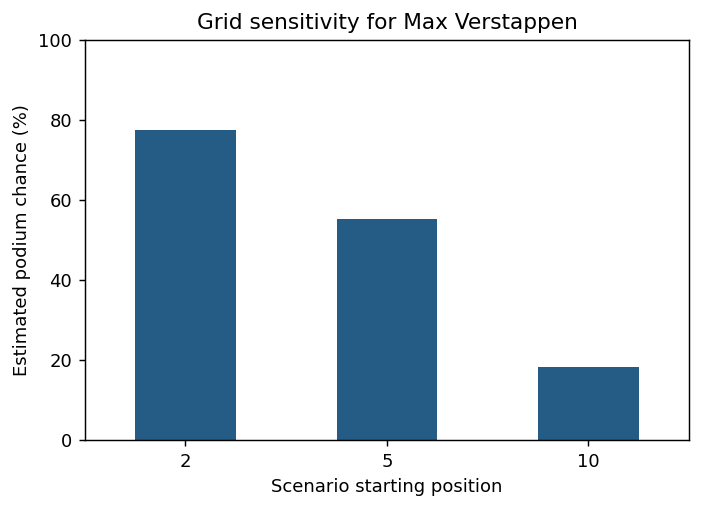

## Can the podium percentages be trusted?

Recent form helped one probability metric and hurt the other. Log loss, which strongly penalises confident misses, improved from **0.2390 to 0.2297**. The Brier score, which averages squared probability errors, worsened from **0.0666 to 0.0707**. Lower is better for both. Among the 38 entries assigned a 40–60% chance, the model averaged 49.7% and the observed podium rate was 44.7%. The highest probability band contained only three entries.

The model uses information available once the grid is known. A crash, mechanical failure or mid-race strategy change can move a driver many places. This test covers one partial season and answers a pre-race forecasting question.

## Reproduce the analysis

GitHub displays the saved charts and results. To rerun the analysis, download this notebook, open it in Jupyter or VS Code, select a Python kernel and **Run All**. Keep the notebook in the kernel’s working directory. The modelling data are embedded in the file and can be read offline. If setting up a fresh environment, install the dependencies with `python -m pip install pandas numpy matplotlib scikit-learn ipykernel`.

**Data provenance.** The snapshot contains the fields used from the project’s supplied races, drivers and results CSVs. Driver history starts in 2010. Training starts in 2014. Each 2026 race is held out until every prediction for that race has been generated. The original CSV publisher and redistribution terms were not supplied.

In [1]:
from pathlib import Path
import base64
import gzip
import io
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


# Load the modelling tables embedded in this notebook.
def find_snapshot():
    paths = sorted(Path.cwd().glob('*.ipynb'), key=lambda p: p.name != 'F1_Race_Analysis.ipynb')
    for path in paths:
        metadata = json.loads(path.read_text(encoding='utf-8')).get('metadata', {})
        if 'f1_forecast_snapshot' in metadata:
            return metadata['f1_forecast_snapshot']
    raise FileNotFoundError('Run from the folder containing this notebook.')

snapshot = find_snapshot()

def read_table(name):
    csv_bytes = gzip.decompress(base64.b64decode(snapshot[name]))
    return pd.read_csv(io.BytesIO(csv_bytes))

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})

races = read_table('races')[['raceId', 'year', 'round', 'date', 'name']]
drivers = read_table('drivers')[['driverId', 'forename', 'surname']]
drivers['driver'] = drivers['forename'] + ' ' + drivers['surname']

results = read_table('results')
history = results[['raceId', 'driverId', 'constructorId', 'grid', 'positionOrder']].merge(
    races, on='raceId', validate='many_to_one'
)
# Modern modelling era has one result per driver per race.
history = history.loc[history.year.ge(2010)].copy()
assert not history.duplicated(['raceId', 'driverId']).any()
for column in ['grid', 'positionOrder']:
    history[column] = pd.to_numeric(history[column], errors='coerce')
history = history.sort_values(['date', 'round', 'raceId']).reset_index(drop=True)
print(f'{len(history):,} driver entries across {history.raceId.nunique():,} races')
print(f"Entries without a numbered grid: {(~history.grid.gt(0)).sum():,}")
print(f"Entries without a finishing order: {history.positionOrder.isna().sum():,}")

7,377 driver entries across 350 races
Entries without a numbered grid: 105
Entries without a finishing order: 0


### The starting-grid benchmark

The diagonal marks a driver finishing in their starting position. The 2025 sample provides a reference before the 2026 test.

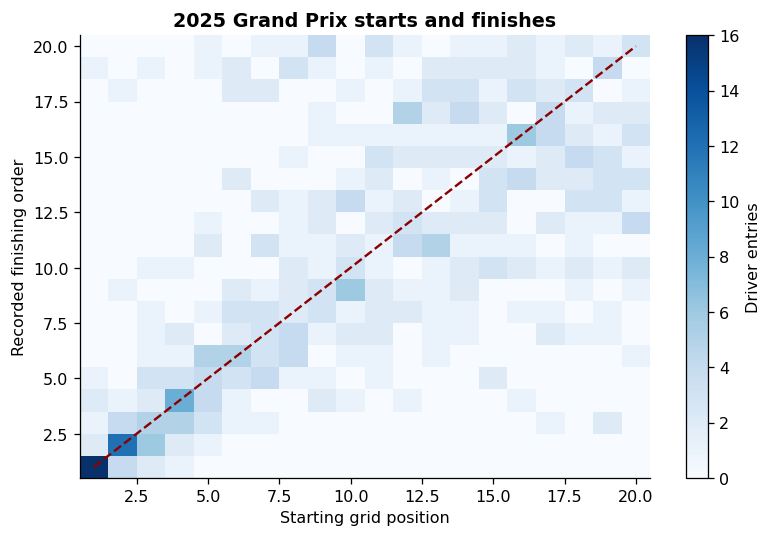

2025 starting-grid benchmark: 3.32 places


In [2]:
eligible = history.loc[history.grid.gt(0) & history.positionOrder.notna()]
recent = eligible.loc[eligible.year.eq(2025)]
fig, ax = plt.subplots(figsize=(8, 5))
bins = np.arange(0.5, max(recent.grid.max(), recent.positionOrder.max()) + 1.5)
counts = ax.hist2d(recent.grid, recent.positionOrder, bins=bins, cmap='Blues')
ax.plot([1, bins[-1] - 0.5], [1, bins[-1] - 0.5], '--', color='darkred')
ax.set(xlabel='Starting grid position', ylabel='Recorded finishing order',
       title='2025 Grand Prix starts and finishes')
fig.colorbar(counts[3], ax=ax, label='Driver entries')
plt.show()
print(f'2025 starting-grid benchmark: {mean_absolute_error(recent.positionOrder, recent.grid):.2f} places')

### Measuring form without looking ahead

Each driver’s rolling average ends one race before the prediction. For teams, both cars are averaged within each weekend before the five-race window is calculated. Missing history is filled using the mean from the training fold.

In [3]:
def add_form(entries):
    entries = entries.sort_values(['date', 'round', 'raceId']).copy()
    entries['driver_form'] = entries.groupby('driverId')['positionOrder'].transform(
        lambda finishes: finishes.shift().rolling(5, min_periods=1).mean()
    )
    team_races = entries.groupby(
        ['constructorId', 'raceId', 'date', 'round'], as_index=False
    )['positionOrder'].mean().sort_values(['date', 'round', 'raceId'])
    team_races['team_form'] = team_races.groupby('constructorId')['positionOrder'].transform(
        lambda finishes: finishes.shift().rolling(5, min_periods=1).mean()
    )
    return entries.merge(
        team_races[['constructorId', 'raceId', 'team_form']],
        on=['constructorId', 'raceId'], validate='many_to_one'
    )

grid_features = ['grid']
form_features = ['grid', 'driver_form', 'team_form']
features = add_form(history)
model_data = features.loc[features.grid.gt(0) & features.positionOrder.notna()].copy()
model_data['podium'] = model_data.positionOrder.le(3).astype(int)

### Replaying the season in race order

For each round, train fresh linear and logistic regressions on earlier dates. Use the same eligible drivers for every comparison. The grid benchmark is scored directly without fitting a model.

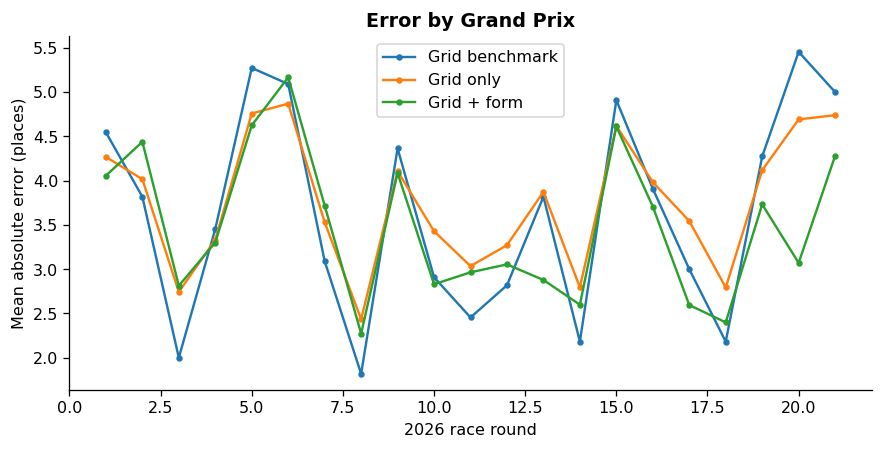

462 entries across 21 races
Grid benchmark    3.636
Grid only         3.759
Grid + form       3.486
Grid benchmark MAE minus grid + form MAE: +0.151 places
Grid-only regression MAE minus grid + form MAE: +0.274 places


In [4]:
def fit_models(training):
    return {
        'Grid only': make_pipeline(SimpleImputer(), LinearRegression()).fit(
            training[grid_features], training.positionOrder),
        'Grid + form': make_pipeline(SimpleImputer(), LinearRegression()).fit(
            training[form_features], training.positionOrder),
        'Podium grid only': make_pipeline(SimpleImputer(), StandardScaler(), LogisticRegression()).fit(
            training[grid_features], training.podium),
        'Podium grid + form': make_pipeline(SimpleImputer(), StandardScaler(), LogisticRegression()).fit(
            training[form_features], training.podium),
    }

modern = model_data.loc[model_data.year.ge(2014)]
predictions = []
for race_id, race in modern.loc[modern.year.eq(2026)].groupby('raceId', sort=False):
    race = race.copy()
    training = modern.loc[modern.date.lt(race.date.iloc[0])]
    assert set(training.raceId).isdisjoint(race.raceId)
    models = fit_models(training)
    race['Grid benchmark'] = race.grid
    race['Grid only'] = models['Grid only'].predict(race[grid_features])
    race['Grid + form'] = models['Grid + form'].predict(race[form_features])
    race['Podium grid only'] = models['Podium grid only'].predict_proba(race[grid_features])[:, 1]
    race['Podium grid + form'] = models['Podium grid + form'].predict_proba(race[form_features])[:, 1]
    race['training_podium_rate'] = training.podium.mean()
    predictions.append(race)

backtest = pd.concat(predictions, ignore_index=True)
finish_columns = ['Grid benchmark', 'Grid only', 'Grid + form']
metrics = pd.Series(
    {column: mean_absolute_error(backtest.positionOrder, backtest[column])
     for column in finish_columns}, name='MAE in places'
)
print(f'{len(backtest)} entries across {backtest.raceId.nunique()} races')
print(metrics.round(3).to_string())
difference = metrics['Grid benchmark'] - metrics['Grid + form']
form_difference = metrics['Grid only'] - metrics['Grid + form']
print(f'Grid benchmark MAE minus grid + form MAE: {difference:+.3f} places')
print(f'Grid-only regression MAE minus grid + form MAE: {form_difference:+.3f} places')

race_error = backtest[finish_columns].sub(backtest.positionOrder, axis=0).abs()
race_error = race_error.groupby(backtest['round']).mean()
ax = race_error.plot(figsize=(9, 4), marker='o', markersize=3)
ax.set(xlabel='2026 race round', ylabel='Mean absolute error (places)', title='Error by Grand Prix')
plt.show()

### Evaluating podium probabilities

Compare each classifier against the historical podium rate. The diagonal in the calibration chart marks agreement between forecast probabilities and observed frequencies.

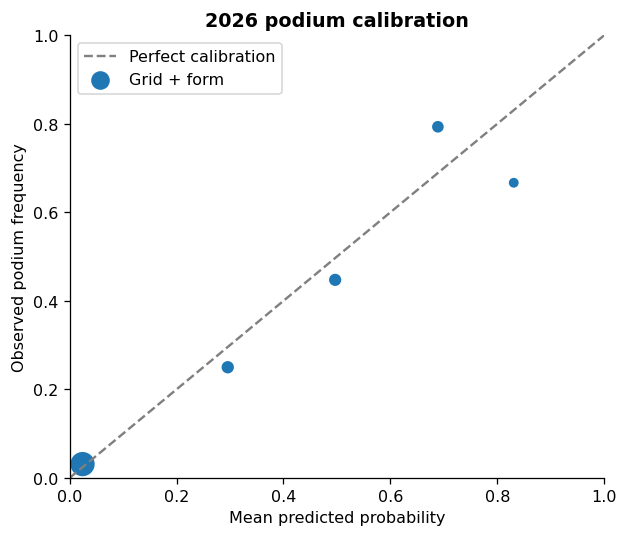

                      Brier score  Log loss
Model                                      
training_podium_rate       0.1180    0.3990
Podium grid only           0.0666    0.2390
Podium grid + form         0.0707    0.2297
                    predicted  observed  entries
Podium grid + form                              
(-0.001, 0.2]           0.024     0.031      352
(0.2, 0.4]              0.296     0.250       40
(0.4, 0.6]              0.497     0.447       38
(0.6, 0.8]              0.689     0.793       29
(0.8, 1.0]              0.831     0.667        3


In [5]:
probability_columns = ['training_podium_rate', 'Podium grid only', 'Podium grid + form']
scores = pd.DataFrame([
    {'Model': column,
     'Brier score': brier_score_loss(backtest.podium, backtest[column]),
     'Log loss': log_loss(backtest.podium, backtest[column])}
    for column in probability_columns
]).set_index('Model')
print(scores.round(4).to_string())

probability = backtest['Podium grid + form']
bands = pd.cut(probability, np.linspace(0, 1, 6), include_lowest=True)
calibration = backtest.groupby(bands, observed=True).agg(
    predicted=('Podium grid + form', 'mean'), observed=('podium', 'mean'),
    entries=('podium', 'size')
)
print(calibration.round(3).to_string())
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], '--', color='grey', label='Perfect calibration')
ax.scatter(calibration.predicted, calibration.observed, s=25 + calibration.entries / 2,
           label='Grid + form')
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted probability',
       ylabel='Observed podium frequency', title='2026 podium calibration')
ax.legend()
plt.show()

### Las Vegas replay and grid experiment

The table covers the whole numbered grid. The scenario below changes only Verstappen’s grid input.

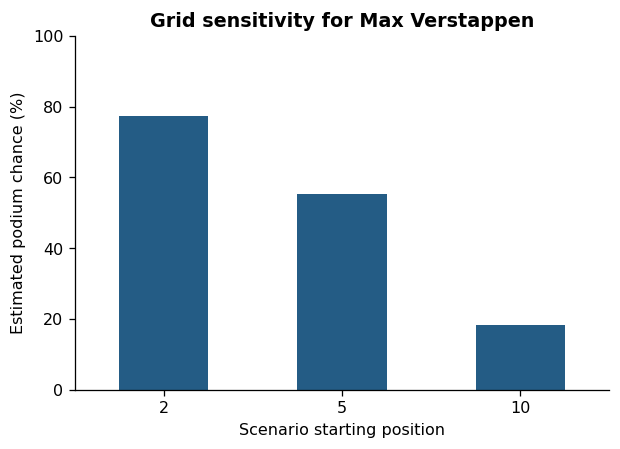

Las Vegas Grand Prix
               driver  grid  Grid + form  Podium grid + form  positionOrder
       Max Verstappen   1.0         3.31                0.83              1
         Lando Norris   3.0         5.25                0.55              2
         Isack Hadjar   4.0         5.27                0.50             15
       George Russell   2.0         5.56                0.50              9
Andrea Kimi Antonelli   6.0         6.13                0.35              4
      Charles Leclerc  10.0         7.34                0.14             10
       Lewis Hamilton  11.0         7.86                0.10              7
          Liam Lawson   7.0         8.60                0.10             14
       Arvid Lindblad   5.0         8.71                0.10             20
        Oscar Piastri  17.0        11.19                0.01              3
         Pierre Gasly   8.0        11.52                0.02              5
      Nico Hülkenberg  12.0        12.02                0.01       

In [6]:
last_race = backtest.loc[backtest.date.eq(backtest.date.max())].copy()
last_race = last_race.merge(drivers[['driverId', 'driver']], on='driverId', validate='many_to_one')
print(last_race.name.iloc[0])
print(last_race.sort_values('Grid + form')[
    ['driver', 'grid', 'Grid + form', 'Podium grid + form', 'positionOrder']
].round(2).to_string(index=False))

pole = last_race.sort_values('grid').iloc[0]
scenario = pd.DataFrame({
    'grid': [2, 5, 10],
    'driver_form': pole.driver_form,
    'team_form': pole.team_form,
})
race_models = fit_models(modern.loc[modern.date.lt(pole.date)])
scenario['Estimated finish'] = race_models['Grid + form'].predict(scenario[form_features])
scenario['Podium chance (%)'] = 100 * race_models['Podium grid + form'].predict_proba(
    scenario[form_features]
)[:, 1]
print(f'Grid scenarios for {pole.driver}')
print(scenario[['grid', 'Estimated finish', 'Podium chance (%)']].round(1).to_string(index=False))
ax = scenario.plot.bar(x='grid', y='Podium chance (%)', legend=False, color='#245c85', figsize=(6, 4))
ax.set(xlabel='Scenario starting position', ylabel='Estimated podium chance (%)',
       ylim=(0, 100), title=f'Grid sensitivity for {pole.driver}')
plt.xticks(rotation=0)
plt.show()

### Forecasting another Grand Prix

The function below accepts a DataFrame with driver ID, constructor ID and starting position. To run it with a published grid, place a file named `future_grid.csv` beside the notebook and set the desired race ID. The default selects the first pending event. Pending dates reflect the bundled snapshot.

In [7]:
pending = races.loc[
    races.date.gt(history.date.max()) & ~races.raceId.isin(history.raceId)
].sort_values('date')
print(pending[['raceId', 'date', 'name']].head().to_string(index=False))

def forecast_race(race_id, starting_grid):
    race_info = pending.set_index('raceId').loc[race_id]
    candidates = starting_grid[['driverId', 'constructorId', 'grid']].copy()
    if (candidates.empty or candidates.isna().any().any()
        or candidates.driverId.duplicated().any() or candidates.grid.duplicated().any()
        or not candidates.grid.gt(0).all() or not candidates.grid.mod(1).eq(0).all()):
        raise ValueError('Supply one row per driver and a unique, positive integer grid position.')
    candidates = candidates.assign(
        raceId=race_id, date=race_info.date, round=race_info['round'],
        year=race_info.year, name=race_info['name'], positionOrder=np.nan
    )
    combined = pd.concat([history.loc[history.date.lt(race_info.date)], candidates], ignore_index=True)
    forecast = add_form(combined).query('raceId == @race_id').copy()
    models = fit_models(modern.loc[modern.date.lt(race_info.date)])
    forecast['Estimated finish'] = models['Grid + form'].predict(forecast[form_features])
    forecast['Podium chance (%)'] = 100 * models['Podium grid + form'].predict_proba(
        forecast[form_features]
    )[:, 1]
    return forecast.merge(drivers[['driverId', 'driver']], on='driverId', how='left')[
        ['driverId', 'driver', 'grid', 'Estimated finish', 'Podium chance (%)']
    ].sort_values('Estimated finish')

grid_path = Path('future_grid.csv')
if grid_path.exists() and not pending.empty:
    selected_race_id = pending.raceId.iloc[0]  # Change to select another listed race.
    print(forecast_race(selected_race_id, pd.read_csv(grid_path)).round(2).to_string(index=False))
else:
    print('A future forecast will run when you supply future_grid.csv for a listed race.')

 raceId       date                 name
   1190 2026-11-29     Qatar Grand Prix
   1191 2026-12-06 Abu Dhabi Grand Prix
A future forecast will run when you supply future_grid.csv for a listed race.


### Reproducibility checks

Verify that each driver appears once per held-out race, that the fold count matches the report and that the model reproduces the published finishing-position error.

In [8]:
assert not backtest.duplicated(['raceId', 'driverId']).any()
assert backtest.raceId.nunique() == 21 and len(backtest) == 462
assert round(metrics['Grid + form'], 2) == 3.49
assert backtest['Podium grid + form'].between(0, 1).all()
print('All four checks passed.')

All four checks passed.
